In [ ]:
# @title 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# @title 2. Konfigurasi
import os, glob

GDRIVE_DIR = '/content/drive/MyDrive/adm'
PREDICT_SPLIT = 'validasi'   # 'validasi' atau 'test'
WORK = '/content/data'

# Hyperparameter
N_FOLDS = 5
EPOCHS  = 30
BATCH   = 128
LR      = 2e-3
WIDTH   = 32
SEED    = 0

# Cari zip berdasarkan kata kunci pada nama file. Isi manual jika nama file berbeda.
zips = sorted(glob.glob(f'{GDRIVE_DIR}/*.zip'))
print('Zip ditemukan:', [os.path.basename(z) for z in zips])

def pick(keyword):
    m = [z for z in zips if keyword in os.path.basename(z).lower()]
    return m[0] if m else None

ZIP_TRAIN = pick('latih')
ZIP_PRED  = pick(PREDICT_SPLIT)
print('Train :', ZIP_TRAIN)
print('Predict:', ZIP_PRED)
assert ZIP_TRAIN and ZIP_PRED, 'Zip tidak ketemu, set ZIP_TRAIN / ZIP_PRED secara manual'

Zip ditemukan: ['data_latih.zip', 'data_validasi.zip', 'submission_validasi (1).zip', 'submission_validasi.zip']
Train : /content/drive/MyDrive/adm/data_latih.zip
Predict: /content/drive/MyDrive/adm/data_validasi.zip


In [ ]:
# @title 3. Unzip ke session
import zipfile, shutil

def extract(zip_path, dest):
    shutil.rmtree(dest, ignore_errors=True)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(dest)

def find_root(dest, marker):
    # Zip kadang punya folder pembungkus, jadi cari folder yang berisi file penanda
    for r, _, files in os.walk(dest):
        if marker in files:
            return r
    raise FileNotFoundError(f'{marker} tidak ada di {dest}')

extract(ZIP_TRAIN, f'{WORK}/latih')
extract(ZIP_PRED,  f'{WORK}/{PREDICT_SPLIT}')

TRAIN_DIR = find_root(f'{WORK}/latih', 'train_labels.csv')
TEST_DIR  = find_root(f'{WORK}/{PREDICT_SPLIT}', 'sample_submission.csv')
print('TRAIN_DIR:', TRAIN_DIR)
print('TEST_DIR :', TEST_DIR)

TRAIN_DIR: /content/data/latih
TEST_DIR : /content/data/validasi


In [ ]:
# @title 4. Import & seed
import csv, math, random
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_amp = device.type == 'cuda'
print('Device:', device)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

set_seed(SEED)

Device: cuda


In [ ]:
# @title 5. Load & normalisasi data
def read_csv(path):
    with open(path, encoding='utf-8') as f:
        return list(csv.DictReader(f))

def load_images(folder, ids):
    return np.stack([
        np.asarray(Image.open(f'{folder}/{i}.png').convert('L'), dtype=np.float32) for i in ids
    ]) / 255.0

def normalize(X):
    # Samakan konvensi: goresan terang di latar gelap, kontras diregangkan ke 0..1 per gambar
    border = np.concatenate([X[:, 0, :], X[:, -1, :], X[:, :, 0], X[:, :, -1]], axis=1).mean(1)
    X = np.where(border[:, None, None] > 0.5, 1 - X, X)
    mn = X.min((1, 2), keepdims=True); mx = X.max((1, 2), keepdims=True)
    return ((X - mn) / (mx - mn + 1e-6)).astype(np.float32)

train_rows = read_csv(f'{TRAIN_DIR}/train_labels.csv')
test_ids = [r['id'] for r in read_csv(f'{TEST_DIR}/sample_submission.csv')]

X = normalize(load_images(f'{TRAIN_DIR}/train', [r['id'] for r in train_rows]))
X_test = normalize(load_images(f'{TEST_DIR}/test', test_ids))
y_raw = np.array([int(r['label']) for r in train_rows])
writer = np.array([int(r['writer_id']) for r in train_rows])

classes = np.unique(y_raw)               # pemetaan label asli <-> indeks 0..K-1
y = np.searchsorted(classes, y_raw)
N_CLASSES = len(classes)

X_t  = torch.from_numpy(X)[:, None].to(device)
y_t  = torch.from_numpy(y).long().to(device)
Xte_t = torch.from_numpy(X_test)[:, None].to(device)
print(f'Train {X.shape} | Test {X_test.shape} | Kelas {N_CLASSES} | Penulis {len(np.unique(writer))}')

Train (10500, 64, 64) | Test (2466, 64, 64) | Kelas 15 | Penulis 70


In [ ]:
# @title 6. Augmentasi (GPU)
def warp(x, angle, scale, tx, ty, shear, flow=None):
    """Affine + (opsional) distorsi elastis dalam satu grid_sample."""
    B = x.size(0)
    cos, sin = torch.cos(angle), torch.sin(angle)
    theta = torch.zeros(B, 2, 3, device=x.device)
    theta[:, 0, 0] = cos / scale
    theta[:, 0, 1] = -sin / scale + shear
    theta[:, 0, 2] = tx
    theta[:, 1, 0] = sin / scale
    theta[:, 1, 1] = cos / scale
    theta[:, 1, 2] = ty
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    if flow is not None:
        grid = grid + flow.permute(0, 2, 3, 1)
    return F.grid_sample(x, grid, padding_mode='zeros', align_corners=False)

def gaussian_blur(x, sigma, k=5):
    ax = torch.arange(k, device=x.device) - k // 2
    g = torch.exp(-(ax ** 2) / (2 * sigma ** 2)); g = (g / g.sum()).float()
    x = F.conv2d(F.pad(x, (k // 2, k // 2, 0, 0), mode='replicate'), g.view(1, 1, 1, k))
    return F.conv2d(F.pad(x, (0, 0, k // 2, k // 2), mode='replicate'), g.view(1, 1, k, 1))

@torch.no_grad()
def augment(x):
    B, _, H, W = x.shape
    d = x.device
    r = lambda lo, hi: torch.empty(B, device=d).uniform_(lo, hi)
    p = lambda q: (torch.rand(B, 1, 1, 1, device=d) < q)

    # Geometri: rotasi, skala, geser, shear, distorsi elastis
    flow = F.interpolate(torch.randn(B, 2, 6, 6, device=d) * 0.06, size=(H, W),
                         mode='bicubic', align_corners=False) * p(0.5)
    x = warp(x, r(-15, 15) * math.pi / 180, r(0.8, 1.2), r(-0.12, 0.12), r(-0.12, 0.12), r(-0.2, 0.2), flow)

    # Ketebalan goresan: 0 = tetap, 1 = tebal (3x3), 2 = tipis (erosi), 3 = sangat tebal (5x5)
    mode = torch.randint(0, 4, (B, 1, 1, 1), device=d)
    x = torch.where(mode == 1, F.max_pool2d(x, 3, 1, 1),
        torch.where(mode == 2, -F.max_pool2d(-x, 3, 1, 1),
        torch.where(mode == 3, F.max_pool2d(x, 5, 1, 2), x)))

    # Blur, gamma (kontras), noise
    x = torch.where(p(0.3), gaussian_blur(x, float(np.random.uniform(0.5, 1.3))), x)
    x = x.clamp(0, 1) ** r(0.7, 1.5).view(B, 1, 1, 1)
    x = x + torch.randn_like(x) * 0.03 * p(0.3)

    # Random erasing: potongan acak
    ar = torch.arange(H, device=d)
    h, w = torch.randint(8, 25, (B, 1, 1), device=d), torch.randint(8, 25, (B, 1, 1), device=d)
    y0, x0 = (torch.rand(B, 1, 1, device=d) * (H - h)).long(), (torch.rand(B, 1, 1, device=d) * (W - w)).long()
    box = ((ar.view(1, H, 1) >= y0) & (ar.view(1, H, 1) < y0 + h) &
           (ar.view(1, 1, W) >= x0) & (ar.view(1, 1, W) < x0 + w)).unsqueeze(1)
    x = x * ~(box & p(0.3))
    return x.clamp(0, 1)

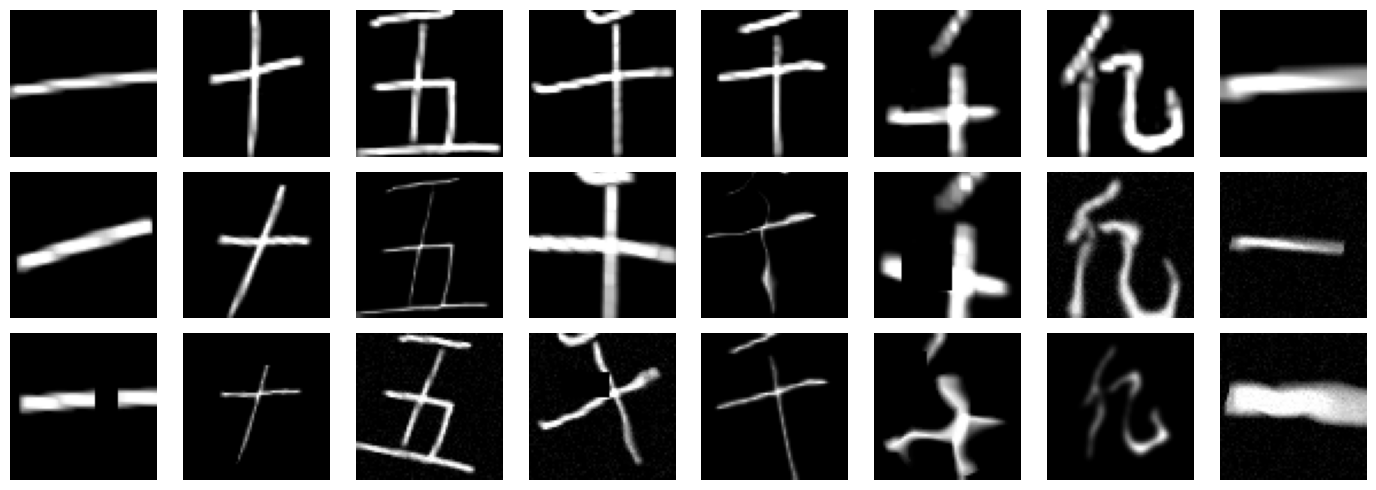

In [ ]:
# @title 7. (Opsional) Cek visual hasil augmentasi
idx = torch.randperm(len(X_t), device=device)[:8]
orig = X_t[idx]
fig, ax = plt.subplots(3, 8, figsize=(14, 5))
for j in range(8):
    ax[0, j].imshow(orig[j, 0].cpu(), cmap='gray')
    ax[1, j].imshow(augment(orig)[j, 0].cpu(), cmap='gray')
    ax[2, j].imshow(augment(orig)[j, 0].cpu(), cmap='gray')
for a in ax.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

In [ ]:
# @title 8. Model CNN
def block(i, o):
    return nn.Sequential(
        nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
        nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
        nn.MaxPool2d(2))

class Net(nn.Module):
    def __init__(self, n_classes, w=32, drop=0.3):
        super().__init__()
        self.features = nn.Sequential(nn.BatchNorm2d(1), block(1, w), block(w, 2 * w),
                                      block(2 * w, 4 * w), block(4 * w, 8 * w))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                  nn.Dropout(drop), nn.Linear(8 * w, n_classes))

    def forward(self, x):
        return self.head(self.features(x))

print(f'Parameter: {sum(p.numel() for p in Net(N_CLASSES, WIDTH).parameters()):,}')

Parameter: 1,176,497


In [ ]:
# @title 8. Model ResNet kecil
class BasicBlock(nn.Module):
    def __init__(self, i, o, stride):
        super().__init__()
        self.conv1 = nn.Conv2d(i, o, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(o)
        self.conv2 = nn.Conv2d(o, o, 3, 1, 1, bias=False);      self.bn2 = nn.BatchNorm2d(o)
        self.short = None
        if stride != 1 or i != o:   # sesuaikan dimensi jalur shortcut
            self.short = nn.Sequential(nn.Conv2d(i, o, 1, stride, bias=False), nn.BatchNorm2d(o))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.bn2(self.conv2(out))
        return F.relu(out + (x if self.short is None else self.short(x)), inplace=True)

class Net(nn.Module):
    def __init__(self, n_classes, w=32, drop=0.3, blocks=(2, 2, 2, 2)):
        super().__init__()
        layers, i = [nn.BatchNorm2d(1),
                     nn.Conv2d(1, w, 3, 1, 1, bias=False), nn.BatchNorm2d(w), nn.ReLU(inplace=True)], w
        for s, (n, o) in enumerate(zip(blocks, (w, 2 * w, 4 * w, 8 * w))):
            for b in range(n):
                layers.append(BasicBlock(i, o, stride=2 if (b == 0 and s > 0) or (b == 0 and s == 0) else 1))
                i = o
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                  nn.Dropout(drop), nn.Linear(i, n_classes))

    def forward(self, x):
        return self.head(self.features(x))

print(f'Parameter: {sum(p.numel() for p in Net(N_CLASSES, WIDTH).parameters()):,}')

Parameter: 2,799,409


In [ ]:
# @title 9. Fungsi training & prediksi (dengan TTA)
# (rotasi derajat, skala, geser x, geser y)
TTA = [(0, 1.0, 0, 0), (6, 1.0, 0, 0), (-6, 1.0, 0, 0),
       (0, 0.92, 0, 0), (0, 1.08, 0, 0), (0, 1.0, 0.05, 0.05), (0, 1.0, -0.05, -0.05)]

@torch.no_grad()
def predict_proba(model, X, tta=True):
    model.eval()
    cfgs = TTA if tta else TTA[:1]
    outs = []
    for i in range(0, len(X), 512):
        xb = X[i:i + 512]; B = xb.size(0)
        full = lambda v: torch.full((B,), float(v), device=device)
        p = 0
        for a, s, tx, ty in cfgs:
            xt = warp(xb, full(a * math.pi / 180), full(s), full(tx), full(ty), full(0))
            with torch.autocast(device_type=device.type, enabled=use_amp):
                p = p + F.softmax(model(xt).float(), 1)
        outs.append(p / len(cfgs))
    return torch.cat(outs)

def train_fold(tr_idx, va_idx, seed):
    set_seed(seed)
    model = Net(N_CLASSES, WIDTH).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=5e-4)
    steps = math.ceil(len(tr_idx) / BATCH)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, epochs=EPOCHS, steps_per_epoch=steps)
    scaler = torch.amp.GradScaler(enabled=use_amp)
    crit = nn.CrossEntropyLoss(label_smoothing=0.1)
    tr = torch.as_tensor(tr_idx, device=device)
    va = torch.as_tensor(va_idx, device=device)

    for ep in range(EPOCHS):
        model.train()
        perm = tr[torch.randperm(len(tr), device=device)]
        for i in range(0, len(perm), BATCH):
            b = perm[i:i + BATCH]
            xb, yb = augment(X_t[b]), y_t[b]
            with torch.autocast(device_type=device.type, enabled=use_amp):
                loss = crit(model(xb), yb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        if (ep + 1) % 5 == 0 or ep == 0:
            acc = (predict_proba(model, X_t[va], tta=False).argmax(1) == y_t[va]).float().mean().item()
            print(f'  epoch {ep + 1:02d}/{EPOCHS} | loss {loss.item():.3f} | val acc {acc:.4f}')
    return model

In [ ]:
# @title 10. Training GroupKFold (per penulis) + ensemble
gkf = GroupKFold(n_splits=N_FOLDS)
test_probs = torch.zeros(len(Xte_t), N_CLASSES, device=device)
fold_acc = []

for f, (tr_idx, va_idx) in enumerate(gkf.split(X, y, groups=writer)):
    print(f'Fold {f + 1}/{N_FOLDS} | train {len(tr_idx)} | val {len(va_idx)} '
          f'| penulis val {len(np.unique(writer[va_idx]))}')
    model = train_fold(tr_idx, va_idx, seed=SEED + f)

    va = torch.as_tensor(va_idx, device=device)
    acc = (predict_proba(model, X_t[va]).argmax(1) == y_t[va]).float().mean().item()
    fold_acc.append(acc)
    print(f'  >> akurasi fold (TTA): {acc:.4f}')

    test_probs += predict_proba(model, Xte_t)
    del model; torch.cuda.empty_cache()

print(f'\nAkurasi GroupKFold: {np.mean(fold_acc):.4f} ± {np.std(fold_acc):.4f}')

Fold 1/5 | train 8400 | val 2100 | penulis val 14
  epoch 01/30 | loss 1.287 | val acc 0.7648
  epoch 05/30 | loss 0.665 | val acc 0.9329
  epoch 10/30 | loss 0.653 | val acc 0.5405
  epoch 15/30 | loss 0.590 | val acc 0.9981
  epoch 20/30 | loss 0.579 | val acc 0.9981
  epoch 25/30 | loss 0.601 | val acc 0.9986
  epoch 30/30 | loss 0.572 | val acc 0.9986
  >> akurasi fold (TTA): 0.9990
Fold 2/5 | train 8400 | val 2100 | penulis val 14
  epoch 01/30 | loss 1.458 | val acc 0.7143
  epoch 05/30 | loss 0.670 | val acc 0.9957
  epoch 10/30 | loss 0.715 | val acc 0.9962
  epoch 15/30 | loss 0.596 | val acc 0.9981
  epoch 20/30 | loss 0.591 | val acc 0.9981
  epoch 25/30 | loss 0.591 | val acc 0.9981
  epoch 30/30 | loss 0.578 | val acc 0.9986
  >> akurasi fold (TTA): 0.9986
Fold 3/5 | train 8400 | val 2100 | penulis val 14
  epoch 01/30 | loss 1.294 | val acc 0.7190
  epoch 05/30 | loss 0.692 | val acc 0.9919
  epoch 10/30 | loss 0.666 | val acc 0.9924
  epoch 15/30 | loss 0.599 | val acc 0

In [ ]:
# @title 10b. Simpan probabilitas CNN
NAMA = 'resnet'
torch.save(test_probs.cpu(), f'{GDRIVE_DIR}/probs_{NAMA}.pt')

In [ ]:
# @title 11. Buat submission & simpan ke Drive
OUT_DIR = '/content/submission'
os.makedirs(OUT_DIR, exist_ok=True)

pred = classes[test_probs.argmax(1).cpu().numpy()]
csv_path = f'{OUT_DIR}/predictions.csv'
with open(csv_path, 'w', newline='', encoding='utf-8') as f:
    w = csv.writer(f, lineterminator='\n')
    w.writerow(['id', 'label'])
    w.writerows(zip(test_ids, pred.tolist()))

zip_path = f'/content/submission_{PREDICT_SPLIT}.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    z.write(csv_path, arcname='predictions.csv')

shutil.copy(zip_path, GDRIVE_DIR)   # salinan di Drive agar tidak hilang saat session putus
print('Selesai:', zip_path, '| juga disalin ke', GDRIVE_DIR)
print('Distribusi prediksi:', dict(zip(*np.unique(pred, return_counts=True))))

Selesai: /content/submission_validasi.zip | juga disalin ke /content/drive/MyDrive/adm
Distribusi prediksi: {np.int64(0): np.int64(117), np.int64(1): np.int64(197), np.int64(2): np.int64(197), np.int64(3): np.int64(205), np.int64(4): np.int64(186), np.int64(5): np.int64(176), np.int64(6): np.int64(202), np.int64(7): np.int64(175), np.int64(8): np.int64(166), np.int64(9): np.int64(143), np.int64(10): np.int64(190), np.int64(11): np.int64(119), np.int64(12): np.int64(133), np.int64(13): np.int64(144), np.int64(14): np.int64(116)}


Confidence rata-rata: 0.854 | median: 0.909
Gambar dengan confidence < 0.6: 203 dari 2466 (8.2%)


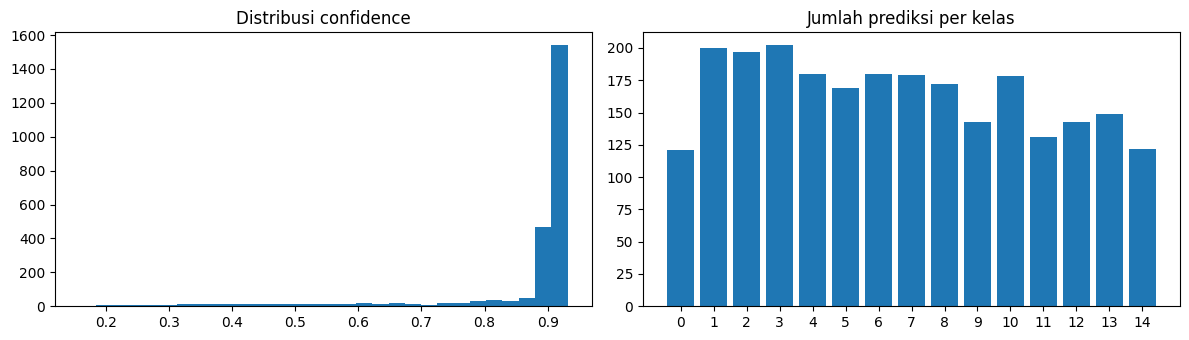

In [ ]:
# @title 12. Confidence prediksi & distribusi kelas
conf_all = (test_probs / N_FOLDS).max(1).values.cpu().numpy()   # test_probs adalah jumlah dari N_FOLDS model
pred_idx = test_probs.argmax(1).cpu().numpy()

print(f'Confidence rata-rata: {conf_all.mean():.3f} | median: {np.median(conf_all):.3f}')
print(f'Gambar dengan confidence < 0.6: {(conf_all < 0.6).sum()} dari {len(conf_all)} ({(conf_all < 0.6).mean():.1%})')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(conf_all, bins=30); ax[0].set_title('Distribusi confidence')
cnt = np.bincount(pred_idx, minlength=N_CLASSES)
ax[1].bar([str(c) for c in classes], cnt); ax[1].set_title('Jumlah prediksi per kelas')
plt.tight_layout(); plt.show()

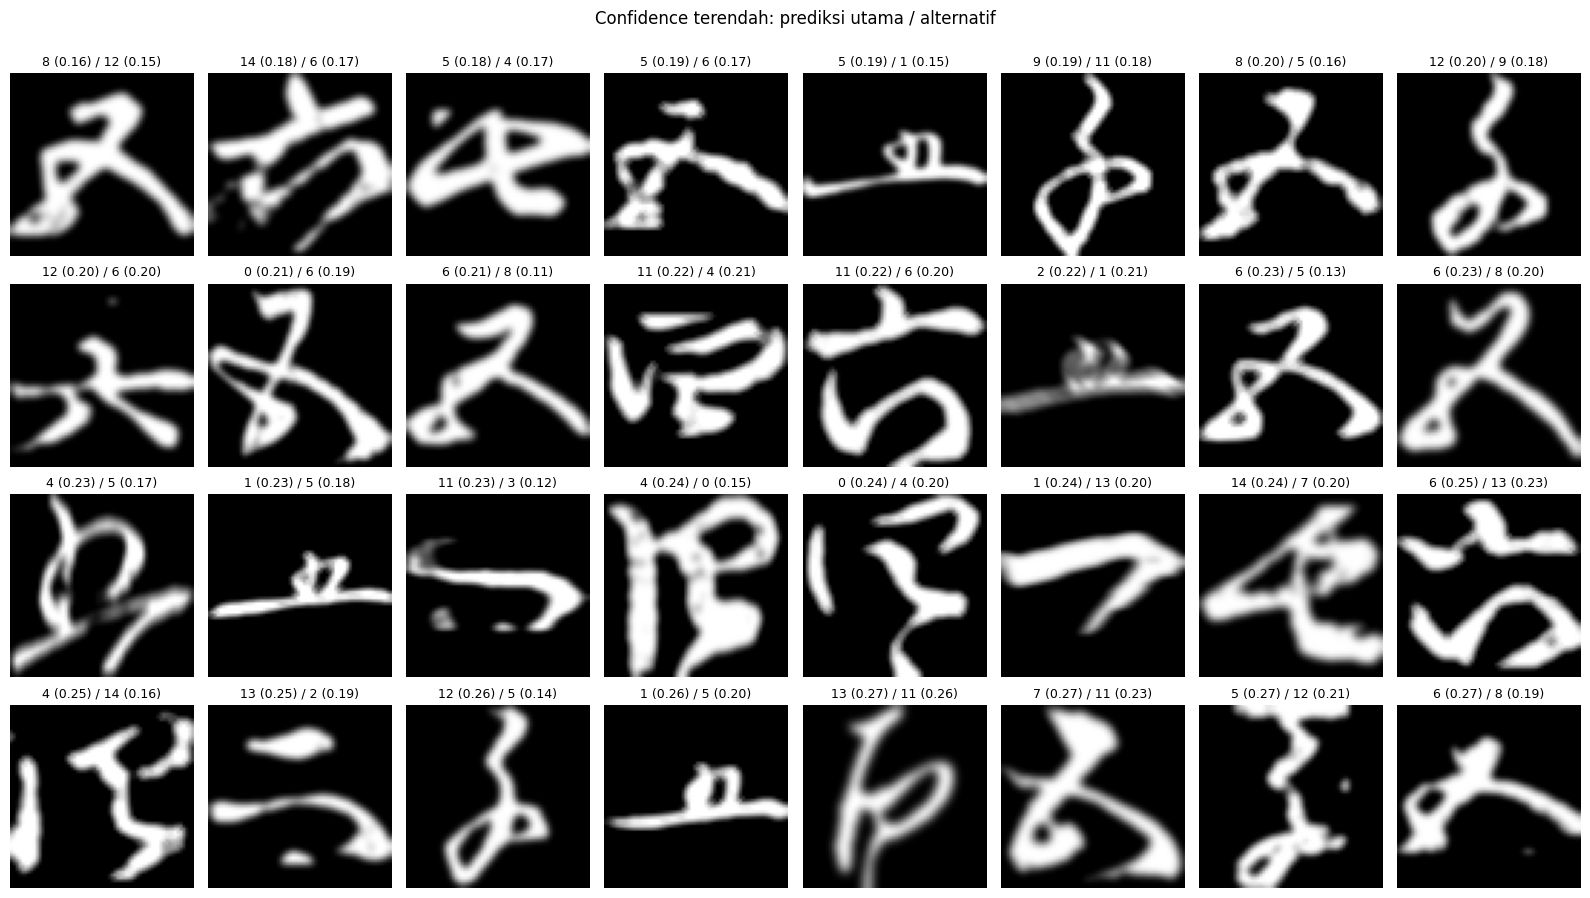

In [ ]:
# @title 13. Gambar dengan confidence terendah
K = 32
low = np.argsort(conf_all)[:K]
fig, ax = plt.subplots(4, 8, figsize=(16, 9))
for a, i in zip(ax.ravel(), low):
    a.imshow(X_test[i], cmap='gray')
    top2 = torch.topk(test_probs[i] / N_FOLDS, 2)
    a.set_title(f'{classes[top2.indices[0].item()]} ({top2.values[0]:.2f}) / '
                f'{classes[top2.indices[1].item()]} ({top2.values[1]:.2f})', fontsize=9)
    a.axis('off')
plt.suptitle('Confidence terendah: prediksi utama / alternatif', y=1.0)
plt.tight_layout(); plt.show()

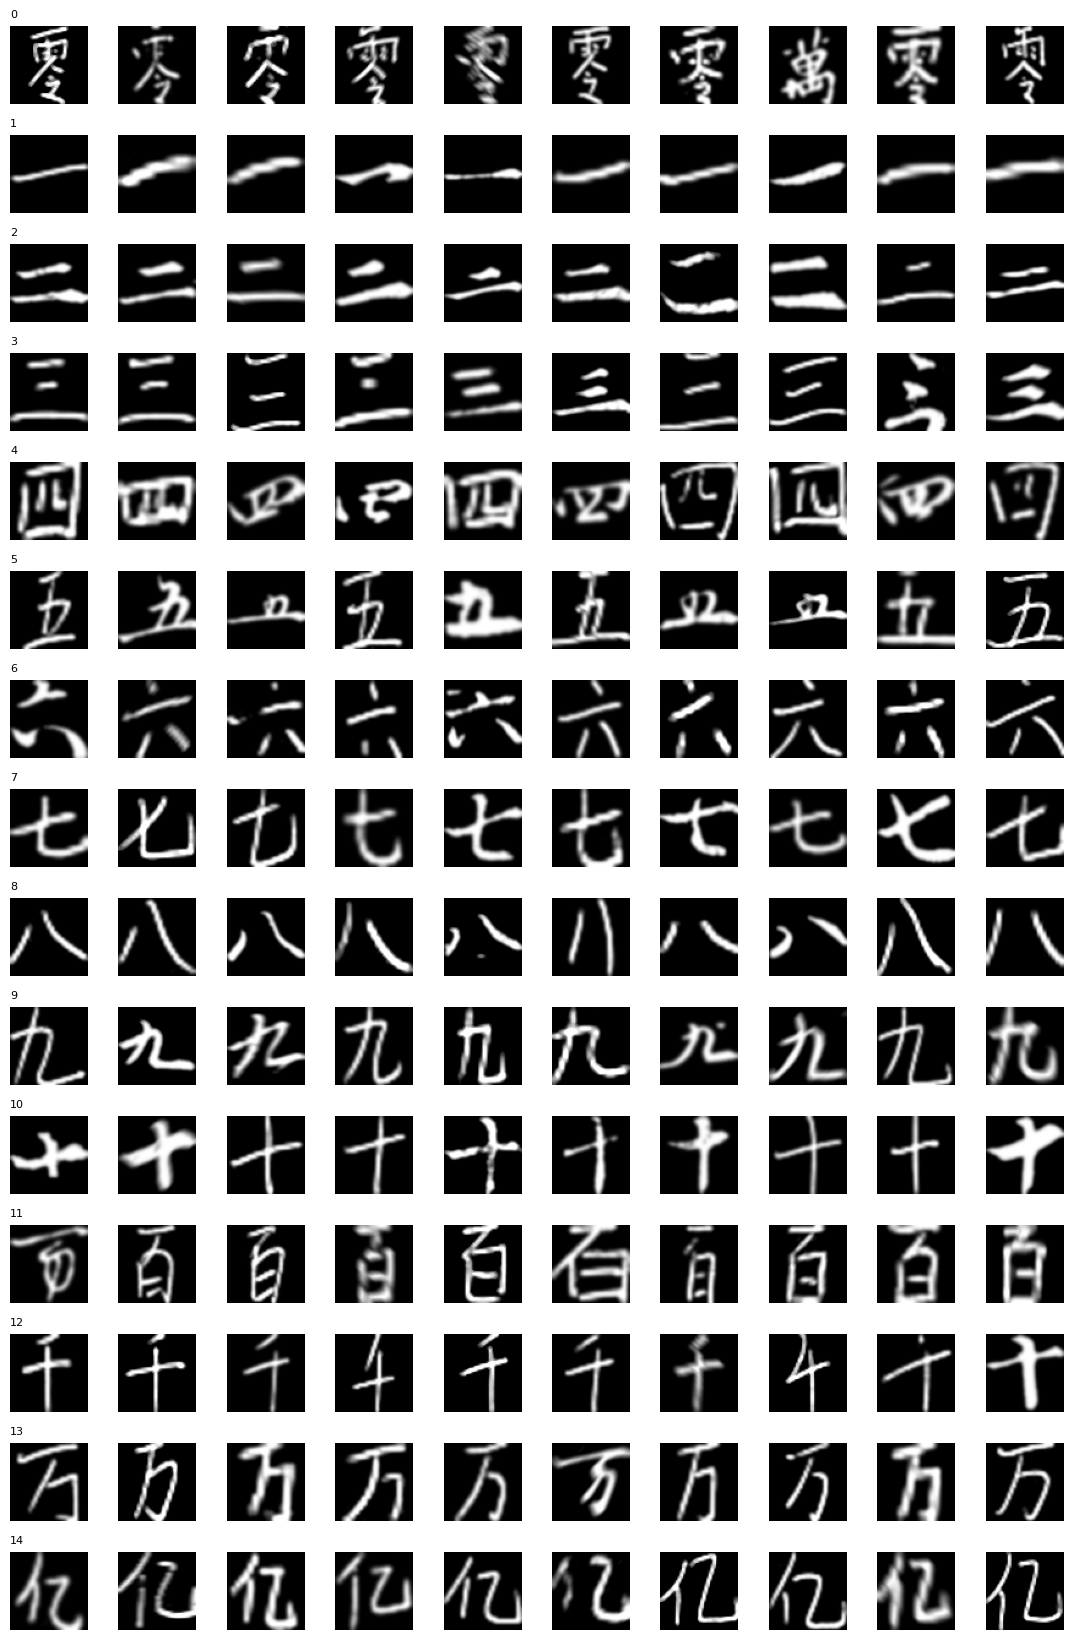

In [ ]:
# @title 14. Contoh gambar per kelas prediksi (cek manual)
# Satu baris = satu kelas prediksi. Gambar yang jelas tidak cocok dengan kelasnya = error.
from scipy.ndimage import distance_transform_edt
n_show = 10
fig, ax = plt.subplots(N_CLASSES, n_show, figsize=(n_show * 1.1, N_CLASSES * 1.1))
rng = np.random.default_rng(0)
for k in range(N_CLASSES):
    idx = np.where(pred_idx == k)[0]
    pick = rng.choice(idx, min(n_show, len(idx)), replace=False) if len(idx) else []
    for j in range(n_show):
        ax[k, j].axis('off')
        if j < len(pick):
            ax[k, j].imshow(X_test[pick[j]], cmap='gray')
    ax[k, 0].set_title(str(classes[k]), fontsize=8, loc='left')
plt.tight_layout(); plt.show()

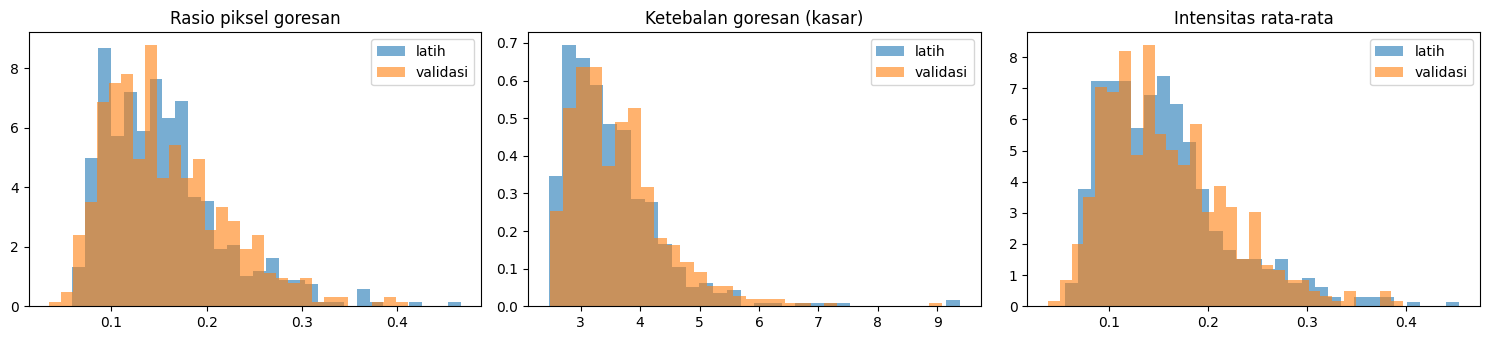

Ketebalan median | latih 3.31 | validasi 3.48


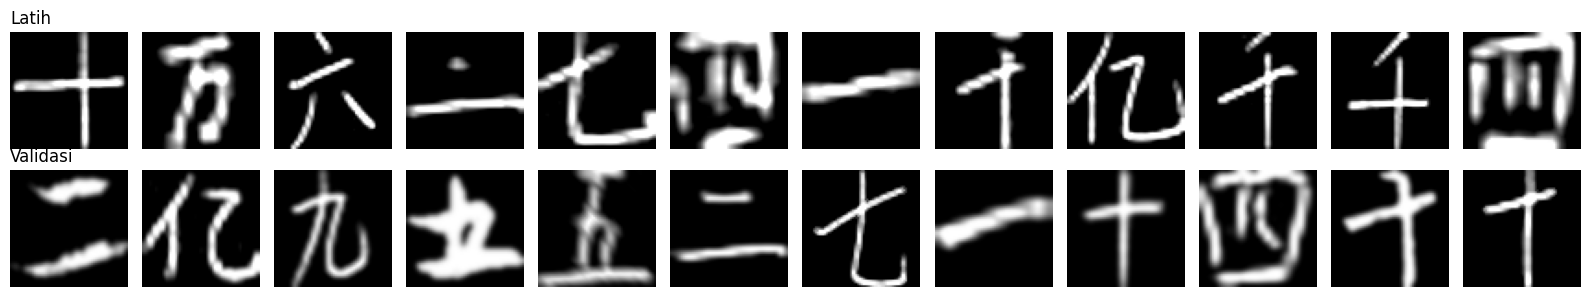

In [ ]:
# @title 15. Perbandingan gaya: data latih vs data validasi
def stats(A, n=500):
    A = A[np.random.default_rng(0).choice(len(A), min(n, len(A)), replace=False)]
    ink = (A > 0.5)
    ratio = ink.mean((1, 2))                               # proporsi piksel goresan
    thick = np.array([2 * distance_transform_edt(m)[m].mean() if m.any() else 0 for m in ink])  # ketebalan kasar (piksel)
    return ratio, thick, A.mean((1, 2))

r_tr, t_tr, m_tr = stats(X)
r_te, t_te, m_te = stats(X_test)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, (u, v, name) in zip(ax, [(r_tr, r_te, 'Rasio piksel goresan'),
                                (t_tr, t_te, 'Ketebalan goresan (kasar)'),
                                (m_tr, m_te, 'Intensitas rata-rata')]):
    a.hist(u, bins=30, alpha=.6, density=True, label='latih')
    a.hist(v, bins=30, alpha=.6, density=True, label='validasi')
    a.set_title(name); a.legend()
plt.tight_layout(); plt.show()
print(f'Ketebalan median | latih {np.median(t_tr):.2f} | validasi {np.median(t_te):.2f}')

# Sampel acak berdampingan
fig, ax = plt.subplots(2, 12, figsize=(16, 3))
for j in range(12):
    ax[0, j].imshow(X[np.random.randint(len(X))], cmap='gray')
    ax[1, j].imshow(X_test[np.random.randint(len(X_test))], cmap='gray')
for a in ax.ravel(): a.axis('off')
ax[0, 0].set_title('Latih', loc='left'); ax[1, 0].set_title('Validasi', loc='left')
plt.tight_layout(); plt.show()

In [ ]:
# @title 16. Pseudo-label dari gambar validasi yang yakin
PSEUDO_THR = 0.85   # confidence rata-rata antar-fold (batas maksimum ~0.93 karena label smoothing)

# Simpan data asli sekali saja agar aman dijalankan ulang
if 'X_base' not in globals():
    X_base, y_base = X_t, y_t
    probs_round0 = test_probs.clone()

conf = (probs_round0 / N_FOLDS).max(1).values
sel = (conf >= PSEUDO_THR).nonzero().squeeze(1)
pseudo_y = probs_round0.argmax(1)[sel]
print(f'Pseudo-label: {len(sel)} dari {len(conf)} gambar ({len(sel) / len(conf):.1%})')

# Data asli di depan, sehingga indeks GroupKFold tetap valid
X_t = torch.cat([X_base, Xte_t[sel]])
y_t = torch.cat([y_base, pseudo_y])
pseudo_idx = np.arange(len(X_base), len(X_t))

Pseudo-label: 2065 dari 2466 gambar (83.7%)


In [ ]:
# @title 17. Training ulang dengan pseudo-label
test_probs = torch.zeros(len(Xte_t), N_CLASSES, device=device)
fold_acc = []

for f, (tr_idx, va_idx) in enumerate(gkf.split(X, y, groups=writer)):
    tr_idx = np.concatenate([tr_idx, pseudo_idx])   # pseudo-label hanya masuk ke train, fold val tetap data asli
    print(f'Fold {f + 1}/{N_FOLDS} | train {len(tr_idx)} | val {len(va_idx)}')
    model = train_fold(tr_idx, va_idx, seed=SEED + 100 + f)

    va = torch.as_tensor(va_idx, device=device)
    acc = (predict_proba(model, X_t[va]).argmax(1) == y_t[va]).float().mean().item()
    fold_acc.append(acc)
    print(f'  >> akurasi fold (TTA): {acc:.4f}')

    test_probs += predict_proba(model, Xte_t)
    del model; torch.cuda.empty_cache()

print(f'\nAkurasi GroupKFold: {np.mean(fold_acc):.4f} ± {np.std(fold_acc):.4f}')
# Opsional: test_probs = test_probs + probs_round0   # ensemble dengan ronde sebelumnya

Fold 1/5 | train 10465 | val 2100
  epoch 01/30 | loss 1.029 | val acc 0.8743
  epoch 05/30 | loss 0.694 | val acc 0.9881
  epoch 10/30 | loss 0.601 | val acc 0.9819
  epoch 15/30 | loss 0.605 | val acc 0.9971
  epoch 20/30 | loss 0.573 | val acc 0.9981
  epoch 25/30 | loss 0.571 | val acc 0.9971
  epoch 30/30 | loss 0.572 | val acc 0.9981
  >> akurasi fold (TTA): 0.9981
Fold 2/5 | train 10465 | val 2100
  epoch 01/30 | loss 1.096 | val acc 0.9052
  epoch 05/30 | loss 0.695 | val acc 0.9943
  epoch 10/30 | loss 0.609 | val acc 0.9976
  epoch 15/30 | loss 0.583 | val acc 0.9986
  epoch 20/30 | loss 0.638 | val acc 0.9990
  epoch 25/30 | loss 0.568 | val acc 0.9990
  epoch 30/30 | loss 0.594 | val acc 0.9986
  >> akurasi fold (TTA): 0.9995
Fold 3/5 | train 10465 | val 2100
  epoch 01/30 | loss 1.194 | val acc 0.8833
  epoch 05/30 | loss 0.639 | val acc 0.9943
  epoch 10/30 | loss 0.619 | val acc 0.9690
  epoch 15/30 | loss 0.602 | val acc 0.9971
  epoch 20/30 | loss 0.615 | val acc 0.998

In [ ]:
# @title 18. Simpan hasil 0.95 ke Drive
# Jalankan SEKARANG, selagi test_probs dan probs_round0 masih ada di memori
TAG = 'validasi_resnet_pseudo_0.95'

# Salin zip dari run terakhir (section 11) dengan nama yang tidak akan tertimpa
shutil.copy(f'/content/submission_{PREDICT_SPLIT}.zip', f'{GDRIVE_DIR}/submission_{TAG}.zip')

# Probabilitas untuk ensemble atau analisis nanti
torch.save({'test_probs': test_probs.cpu(), 'probs_round0': probs_round0.cpu(),
            'test_ids': test_ids, 'classes': classes, 'n_folds': N_FOLDS},
           f'{GDRIVE_DIR}/probs_{TAG}.pt')
print('Tersimpan:', sorted(os.listdir(GDRIVE_DIR)))

Tersimpan: ['README.md', 'baseline.py', 'data_latih.zip', 'data_validasi.zip', 'per_class_recall.csv', 'predictions.csv', 'predictions_val1.csv', 'probs_cnn.pt', 'probs_resnet.pt', 'probs_validasi_resnet_pseudo_0.95.pt', 'resnet18_best_validation.pt', 'resnet18_final_all_train.pt', 'submission_validasi (1).zip', 'submission_validasi.zip', 'submission_validasi_resnet_pseudo_0.95.zip', 'training_history.csv']
